# Source reuse at fixed population width

    **November 15, 2026 · executed exploratory notebook · existing recordings, fresh fits.**

    This is experiment 1 of one fixed two-part study.
    The research question is whether endpoint recovery depends on repeated use of a small
    recorded source pool, and how recovery changes when more sessions/columns are available.
    The first experiment compares 2, 3 and 5 distinct training sources per session × class at
    17 columns and 144 constructed training rows. Its U3 control uses the same B3 sources once
    (27 rows). The second compares 17, 49 and 83 columns at three sources per pool.

    Read top to bottom: question → source eligibility → construction → visible first-case
    training → complete fixed schedule → controls → errors → interpretation. Every reported
    result below is produced by this fresh two-notebook execution. The accepted study defined November14 is
    preserved separately; this reproduction is not an additional biological replicate.

    **What counts as evidence?** Spike times and task-event records are measured. Cue-bin
    counts, pseudopopulation rows, embeddings and predictions are derived. We test association
    with nine ordered start–goal labels in a historically exposed development split. These are
    condition-level rows assembled using known labels, not independently observed simultaneous
    population trials. No exact natural-trial decoding, path prediction or mechanism claim follows.

    **Reading and execution.** Saved outputs require no fitting. Re-execution requires the
    experiment runner, authenticated compact source inputs, the fixed runtime and fresh passing
    gates; it trains models. The companion file shares authenticated B3 fits without refitting.
    Numerical recipes live beside this notebook; the protocol and validation ledger are under
    `docs/experiments/source-reuse-width-20261114/`.

In [1]:
from pathlib import Path
import os
import json
import html
import base64
from IPython.display import display, HTML, Image
from neuro.notebook_artifacts import runtime_identity, stable_kernel_identity
from neuro.studies.population_models import frozen_models
from experiments.source_reuse_width_20261114 import study
from experiments.source_reuse_width_20261114.report import create_report, table
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from scipy.special import softmax
from neuro import cebra
from neuro.pca_lda import fit_standardizer, fit_pca
from neuro.studies.population_models import ENCODERS, DECODERS, fit_native, fit_decoder
from experiments.source_reuse_width_20261114.walkthrough_20261115.execution import PartExecution
PROJECT = Path(os.environ['NEURO_PROJECT_ROOT'])
RUN = Path(os.environ['NEURO_REUSE_RUN'])
PART = 'reuse'
config = json.loads((RUN / 'configuration.json').read_text())
assert config == study.configuration(config['design'])
pins = json.loads((RUN / 'code-pins.json').read_text())
assert all((study.sha(PROJECT / path) == digest for path, digest in pins.items()))
identity = runtime_identity()
assert stable_kernel_identity(identity) == stable_kernel_identity(json.loads((RUN / 'runtime.json').read_text()))
study.write_json(RUN / ('kernel-runtime-' + PART + '.json'), identity)
if PART == 'width':
    assert study.sha(RUN / 'bridge-receipt.json') == os.environ['NEURO_BRIDGE_SHA256']
    bridge = json.loads((RUN / 'bridge-receipt.json').read_text())
    assert all((study.sha(RUN / path) == digest for path, digest in bridge['files_sha256'].items()))
    print('Authenticated8completed B3 bridge cases and their saved artifacts; no bridge refitting.')
print('Classification:', config['classification'])
print('Runtime packages:', identity['packages'])
print('Complete two-experiment budget:', config['expected_fit_counts'])

Classification: exploratory
Runtime packages: {'numpy': '2.3.4', 'scikit-learn': '1.7.2', 'torch': '2.12.0', 'cebra': '0.6.1', 'joblib': '1.5.2', 'nbclient': '0.10.2', 'ipykernel': '6.30.1'}
Complete two-experiment budget: {'cebra': 48, 'knn': 576, 'lda': 576, 'logistic': 576, 'native': 48, 'optimizer_updates': 96000, 'pca': 48, 'svm': 576}


## 1. Fixed task and available measurements

The global current/predecessor contributor embargo is applied before source and population selection. Metadata-only optimization first maximized width with≥5training/≥1development sources per pool, then width with≥3training/≥1development among ties, then selected the lexicographically first class list. All six starts and goals occur once or twice. This uses historically exposed development availability. Nine ordered pairs are not a3×3rectangle or measured maze paths. No performance score selected this panel.

A **session block** supplies columns assigned to the same session/source trial. Same-session grouping does not itself verify simultaneous recording; this study does not establish biological simultaneity within or across blocks.
Different session blocks are joined by the ordered endpoint label. One real source identity
is distinct from another, but adjacent trials and repeated computational seeds are not assumed
independent. Eligibility requires correct current and predecessor trials, valid cue duration
and frozen split membership. The globally protected current/predecessor contributors are
removed from training before any fitting or metadata-based panel optimization. Operational start is the previous successful trial's marker-derived goal; operational goal
is the current trial's marker. Thus start is inferred from task records, not independently
tracked as a position or path. This explains why the previous trial is a contributor and
must be embargoed along with the current trial. These labels remain operational task labels;
compact inputs do not establish place-field
quality or exact navigation trajectories. The three-source source pool is nested within the
five-source pool, and the same classes remain in every arm. No class is deleted between arms.

In [2]:
with frozen_models():
    meta = study.metadata(PROJECT / 'data/cue-source-v1')
    assert study.validate_design(meta, config['design'])
print('Classes:', ', '.join(config['design']['panel']['conditions']))
print('Protected current/predecessor development contributors:', len(meta['protected']))
display(HTML(table([dict(roster=name, **row) for name, row in config['design']['rosters'].items()])))
print('Distinct training sources used: B2=54; B3/U3=81; B5=135; Wmid=297; Wfull=540.')
print('Constructed rows:144train/72development, except U3=27train. These are not independent sample sizes.')
print('Arm | columns | sessions | sources per session/class | constructed train rows | distinct selected train IDs')
for row in [('B2', 17, 3, 2, 144, 54), ('B3', 17, 3, 3, 144, 81), ('B5', 17, 3, 5, 144, 135), ('U3', 17, 3, 3, 27, 81), ('Wmid', 49, 11, 3, 144, 297), ('Wfull', 83, 20, 3, 144, 540)]:
    print(row)
print('All arms have72constructed development rows. Adding columns also adds sessions and sources.')

Classes: 1->2, 1->4, 2->5, 2->6, 3->1, 4->6, 5->3, 5->4, 6->2
Protected current/predecessor development contributors: 5872


roster,available_development_sources,available_train_sources,development_singleton_pools,minimum_development_sources,minimum_train_sources,session_aliases,sessions,units
core,56,160,5,1,5,"['S16', 'S27', 'S34']",3,17
full,365,912,41,1,3,"['S05', 'S06', 'S07', 'S08', 'S16', 'S20', 'S23', 'S25', 'S27', 'S28', 'S29', 'S32', 'S34', 'S38', 'S40', 'S42', 'S43', 'S44', 'S49', 'S50']",20,83
middle,210,543,18,1,3,"['S05', 'S06', 'S07', 'S16', 'S20', 'S23', 'S27', 'S28', 'S34', 'S38', 'S44']",11,49


Distinct training sources used: B2=54; B3/U3=81; B5=135; Wmid=297; Wfull=540.
Constructed rows:144train/72development, except U3=27train. These are not independent sample sizes.
Arm | columns | sessions | sources per session/class | constructed train rows | distinct selected train IDs
('B2', 17, 3, 2, 144, 54)
('B3', 17, 3, 3, 144, 81)
('B5', 17, 3, 5, 144, 135)
('U3', 17, 3, 3, 27, 81)
('Wmid', 49, 11, 3, 144, 297)
('Wfull', 83, 20, 3, 144, 540)
All arms have72constructed development rows. Adding columns also adds sessions and sources.


## 2. Reconstruct authenticated source signals

Selected-unit spike timestamps are counted in ten half-open100-ms bins over cue[0,1)s. Timing uses the validated Ripple clock and cue markers. Missing cross-session measurements stay masked; measured zeros remain zeros. No prior model, embedding or historical prediction initializes this run.

The reconstructed tensor uses source trial × unit × ten cue bins. The bin interval is
[0,1) seconds relative to cue onset; each bin is100ms. Counts are not firing rates unless
divided by0.1s. A source trial only measures its own session's units. Missing other-session
entries must never be treated as silence. Materialization below takes each block from an
observed source before any scaler or model sees a dense pseudopopulation row.

In [3]:
with frozen_models():
    data, reconstruction_audit = study.reconstruct(PROJECT / 'data/cue-source-v1', meta, config['design'])
study.write_json(RUN / ('reconstruction-' + PART + '.json'), reconstruction_audit)
print('Fresh source tensor:', data.values.shape)
print('Recorded units:', len(data.units), 'session blocks:', len(data.block_ids))
print('Overlapping cross-split contributors:', len(data.dependency_audit()['overlapping_contributor_ids']))
prefit = json.loads((RUN / 'prefit-evidence/rank-and-plan-checks.json').read_text())
assert len(prefit) == 48 and min((r['training_rank'] for r in prefit)) >= 7
print('Before fitting:48scheduled plans passed exact source nesting, projected arrays, quotas, contributors and rank≥7.')
display(HTML(table([r for r in prefit if r['world'] == 'observed' and r['seed'] == 0])))
print('Observed source×unit entries:', int(data.observed.sum()), 'of', int(data.observed.size))
print('Ten cue-bin centers (seconds):', np.arange(0.05, 1.0, 0.1).round(2).tolist())
print('No source values, unit identities or trial-lineage arrays are printed in this shareable notebook.')

Fresh source tensor: (1277, 83, 10)
Recorded units: 83 session blocks: 20
Overlapping cross-split contributors: 0
Before fitting:48scheduled plans passed exact source nesting, projected arrays, quotas, contributors and rank≥7.


arm,constant_columns,distinct_train_sources,overlapping_contributors,rows_per_class,seed,sessions,source_budget,training_rank,training_source_extra_draw_fraction,units,world
B2,0,54,0,16,0,3,2,17,0.875,17,observed
B3,0,81,0,16,0,3,3,17,0.8125,17,observed
B5,0,135,0,16,0,3,5,17,0.6875,17,observed
U3,0,81,0,3,0,3,3,17,0,17,observed
Wmid,0,297,0,16,0,11,3,49,0.8125,49,observed
Wfull,0,540,0,16,0,20,3,83,0.8125,83,observed


Observed source×unit entries: 5375 of 105991
Ten cue-bin centers (seconds): [0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95]
No source values, unit identities or trial-lineage arrays are printed in this shareable notebook.


## 3. Paired construction and standard controls

Per-session×class source rankings give nested2⊂3⊂5source sets. The three-source full-width plan is projected into smaller rosters; shared columns retain exactly the same source blocks, row IDs and values. One development plan per label world is projected into every arm. Observed development remains fixed across all three repeats. Balanced cycles cover all selected sources: B2 uses each8times, B3 uses5or6, B5 uses3or4. U3 uses the same B3 sources once. Five joint-pair source-label worlds preserve session/split counts and are generated before selection/assembly. They are diagnostic controls, not biological p-values.

In [4]:
with frozen_models():
    plans = study.paired_plans(data, meta, config['design'], seed=0)
    checked = study.verify_plans(plans)
display(HTML(table([r for r in checked if r['arm'] in study.PART_ARMS[PART]])))
rows = []
for arm in study.PART_ARMS[PART]:
    source, train_plan, dev_plan = plans[arm]
    tuples = [tuple(row.source_ids) for row in train_plan.rows]
    uses = Counter((sid for row in train_plan.rows for sid in row.source_ids))
    rows.append(dict(arm=arm, constructed_rows=len(tuples), distinct_source_IDs=len(uses), min_uses=min(uses.values()), max_uses=max(uses.values()), repeated_whole_source_tuples=len(tuples) - len(set(tuples))))
display(HTML(table(rows)))
print('Tuple repetitions count rows beyond the first identical source-ID combination, not pairwise collisions or numerical-vector equality.')

arm,units,sessions,source_budget,rows_per_class,distinct_train_sources,training_source_extra_draw_fraction,overlapping_contributors
B2,17,3,2,16,54,0.875,0
B3,17,3,3,16,81,0.8125,0
B5,17,3,5,16,135,0.6875,0
U3,17,3,3,3,81,0,0


arm,constructed_rows,distinct_source_IDs,min_uses,max_uses,repeated_whole_source_tuples
B2,144,54,8,8,77
B3,144,81,5,6,23
B5,144,135,3,4,6
U3,27,81,1,1,0


Tuple repetitions count rows beyond the first identical source-ID combination, not pairwise collisions or numerical-vector equality.


## 4. Materialize the first case and start fit accounting

        We now expose one complete case: **B2, observed seed0** in the reuse notebook or
        **Wmid, observed seed0** in the width notebook. The remaining cases use the same
        maintained fitting routine. The staged path must reproduce that routine on invented
        full-width inputs before any biological execution is permitted.

        A training row contains all columns for each chosen session block. Its label is the
        common endpoint class used to choose those blocks. All bins and copies of a source
        stay on one side of the split. The recipe table below shows anonymous blocks and
        dimensions; full source provenance is saved privately and checked independently.

In [5]:
execution = PartExecution(data, meta, config, RUN, PART)
case = execution.begin(plans)
x_train, x_dev = (case.train.values, case.dev.values)
print('First case:', case.case['id'])
print('Train / development tensors:', x_train.shape, x_dev.shape, '= row × column × bin')
print('Endpoint classes:', sorted(set(case.yt['pair'])))
display(HTML(table([dict(block=meta['aliases'][block], columns=sum((u.block_id == block for u in case.data.units))) for block in case.data.block_ids])))
print('Constructed training class counts:', dict(Counter(case.yt['pair'])))
print('Constructed development class counts:', dict(Counter(case.yd['pair'])))
assert np.isfinite(x_train).all() and np.isfinite(x_dev).all()
print('Contributor overlap:0; all materialized values finite.')
recipe = []
for row_number, row in enumerate(case.train.plan.rows[:2]):
    for block_index, block in enumerate(case.data.block_ids):
        pool = sorted({r.source_ids[block_index] for r in case.train.plan.rows if r.condition == row.condition})
        recipe.append(dict(constructed_row=row_number, pair=row.condition, block=meta['aliases'][block], source_choice=1 + pool.index(row.source_ids[block_index])))
display(HTML(table(recipe)))
print('Recipe choices are local ordinal aliases within each session×class pool; equal numbers in different pools are not the same source.')

Fitting observed_seed0_B2


First case: observed_seed0_B2
Train / development tensors: (144, 17, 10) (72, 17, 10) = row × column × bin
Endpoint classes: [np.str_('1->2'), np.str_('1->4'), np.str_('2->5'), np.str_('2->6'), np.str_('3->1'), np.str_('4->6'), np.str_('5->3'), np.str_('5->4'), np.str_('6->2')]


block,columns
S16,3
S27,8
S34,6


Constructed training class counts: {np.str_('1->2'): 16, np.str_('1->4'): 16, np.str_('2->5'): 16, np.str_('2->6'): 16, np.str_('3->1'): 16, np.str_('4->6'): 16, np.str_('5->3'): 16, np.str_('5->4'): 16, np.str_('6->2'): 16}
Constructed development class counts: {np.str_('1->2'): 8, np.str_('1->4'): 8, np.str_('2->5'): 8, np.str_('2->6'): 8, np.str_('3->1'): 8, np.str_('4->6'): 8, np.str_('5->3'): 8, np.str_('5->4'): 8, np.str_('6->2'): 8}
Contributor overlap:0; all materialized values finite.


constructed_row,pair,block,source_choice
0,1->2,S16,2
0,1->2,S27,2
0,1->2,S34,2
1,1->2,S16,1
1,1->2,S27,2
1,1->2,S34,2


Recipe choices are local ordinal aliases within each session×class pool; equal numbers in different pools are not the same source.


## 5. Train-only normalization: check the actual arithmetic

        Pool the training rows and cue bins, yielding N×10 vectors of width D. For each unit
        fit its training mean μ and standard deviation σ, then transform both splits using
        z=(x−μ)/σ. A constant unit uses scale1. No development statistic is fitted.
        Raw whole-cue readouts then flatten unit-major into10D features. This differs from
        the subsequent latent readouts' time-major70features, but every branch retains the
        whole cue. Scalers are learned preprocessing; the displayed2,448 model-fit budget
        excludes scaler fits and records that convention explicitly.

In [6]:
with execution.stage('raw scaling'):
    raw_fit = fit_standardizer(x_train)
    raw_train, raw_dev = case.record_representation('raw', raw_fit)
    pooled = x_train.transpose(0, 2, 1).reshape(-1, x_train.shape[1])
    manual = ((x_dev - raw_fit.scaler.mean_[None, :, None]) / raw_fit.scaler.scale_[None, :, None]).astype(np.float32)
    residual = float(np.max(np.abs(manual - raw_fit.transform(x_dev))))
    np.testing.assert_allclose(raw_fit.scaler.mean_, pooled.mean(0, dtype=np.float64), rtol=1e-07, atol=1e-07)
    np.testing.assert_allclose(manual, raw_fit.transform(x_dev), rtol=1e-05, atol=1e-05)
    print('Training vectors used by scaler:', raw_fit.scaler.n_samples_seen_)
    print('Raw feature shapes:', raw_train.shape, raw_dev.shape)
    print('Maximum manual-versus-library normalization residual:', residual)

Training vectors used by scaler: 1440
Raw feature shapes: (144, 170) (72, 170)
Maximum manual-versus-library normalization residual: 4.76837158203125e-07


## 6. Fit PCA7 and verify its linear projection

        PCA finds seven orthogonal directions of training-bin variance after training-only
        unit scaling. It sees no endpoint labels. Full SVD and a numerical-rank≥7gate avoid
        silently padding unsupported dimensions. For each standardized bin vector z, the
        fitted transform is (z−PCAmean)×componentsᵀ. Concatenating ten7D bin vectors gives
        70 whole-cue readout features. Explained variance is a reconstruction statistic;
        it does not measure endpoint prediction or biological significance.

In [7]:
with execution.stage('PCA training'):
    pca_fit = fit_pca(x_train, n_components=config['output_dimension'])
    pca_train, pca_dev = case.record_representation('pca', pca_fit)
    standardized = pca_fit.standardizer.transform(x_dev).transpose(0, 2, 1).reshape(-1, x_dev.shape[1])
    manual_pca = ((standardized - pca_fit.pca.mean_) @ pca_fit.pca.components_.T).astype(np.float32).reshape(len(x_dev), -1)
    np.testing.assert_allclose(manual_pca, pca_dev, rtol=1e-05, atol=1e-05)
    print('PCA feature shapes:', pca_train.shape, pca_dev.shape)
    print('Explained variance ratios:', pca_fit.pca.explained_variance_ratio_.round(5).tolist())
    print('Maximum manual projection residual:', float(np.max(np.abs(manual_pca - pca_dev))))

PCA feature shapes: (144, 70) (72, 70)
Explained variance ratios: [0.10948999971151352, 0.10006999969482422, 0.089369997382164, 0.07742000371217728, 0.0689999982714653, 0.06818000227212906, 0.06700000166893005]
Maximum manual projection residual: 7.152557373046875e-07


## 7. Fit CEBRA-Time7: what its objective learns

        The Time encoder maps one standardized population bin to seven coordinates. A
        reference and an adjacent bin from the same constructed row form a positive pair;
        negative bins are sampled across rows/time. Cosine InfoNCE favors positive similarity
        relative to negatives. The network is `offset1-model`, hidden32, batch256,
        temperature1, Adam learning-rate0.0003, and exactly1,000updates. Endpoint labels
        label rows for validation but do not choose the Time positives.

        The temporal neighborhood is imposed by pseudopopulation construction. It is not a
        measured simultaneous cross-session neural trajectory. Falling contrastive loss only
        demonstrates optimization of this objective; held-out readouts and diagnostic worlds
        assess endpoint association. Even U3's once-only assembly is revisited during training.

In [8]:
with execution.stage('CEBRA-Time training'):
    time_fit = cebra.fit(x_train, case.train.targets, iterations=config['iterations'], batch_size=config['batch_size'], output_dimension=config['output_dimension'], hidden=config['hidden'], learning_rate=config['learning_rate'], seed=case.case['seed'], max_seconds=config['limits']['cebra_fit_seconds'], device='cpu')
    time_train, time_dev = case.record_representation('cebra', time_fit)
    print(time_fit.solver.model)
    print('Trainable parameters:', sum((p.numel() for p in time_fit.solver.model.parameters() if p.requires_grad)))
    print('Features:', time_train.shape, time_dev.shape, 'updates:', time_fit.diagnostics['iterations'])
    exposure = time_fit.diagnostics['exposure_summary']
    row_draws = np.asarray(exposure['reference_row_counts'])[0]
    print('Reference draws:', int(row_draws.sum()), 'per-row minimum/maximum:', int(row_draws.min()), int(row_draws.max()))

Offset0Model(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=17, out_features=32, bias=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=32, out_features=32, bias=True)
    (4): GELU(approximate='none')
    (5): Linear(in_features=32, out_features=16, bias=True)
    (6): GELU(approximate='none')
    (7): Linear(in_features=16, out_features=7, bias=True)
    (8): _Norm()
    (9): Squeeze()
  )
)
Trainable parameters: 2279
Features: (144, 70) (72, 70) updates: 1000
Reference draws: 256000 per-row minimum/maximum: 1672 1890


## 8. Fit genuine native multisession CEBRA7

        The native comparator fits one network per session through CEBRA's actual
        multisession API. Every session contributes its own unit vector and joint-pair
        labels; positives therefore use pair supervision across sessions. After fitting,
        corresponding per-bin7D embeddings are averaged equally across sessions and ten bins
        are concatenated. Pooling is fixed, not learned. This pipeline changes architecture,
        supervision and aggregation together, so its score cannot isolate a single cause.

        To bound work, each session receives floor(256/S) batch references:85,23or12for
        S=3,11or20, yielding255,253or240total references per update. The notebook shows the
        realized dimensions and counts. Native and Time both train1,000updates; their losses
        have different sampling semantics and should not be ranked against one another.

In [9]:
with execution.stage('native multisession training'):
    native_fit = fit_native(x_train, case.train.targets, case.data.units, case.data.block_ids, config, case.case['seed'])
    native_train, native_dev = case.record_representation('native', native_fit)
    print('Solver:', native_fit.estimator.solver_name_, 'session encoders:', native_fit.estimator.num_sessions_)
    print('Input columns per encoder:', native_fit.diagnostics['session_input_dimensions'])
    print('First session network:', next(native_fit.estimator.model_.children()))
    print('Trainable parameters:', sum((p.numel() for p in native_fit.estimator.model_.parameters() if p.requires_grad)))
    print('Features:', native_train.shape, native_dev.shape)
    print('Batch/session:', native_fit.diagnostics['batch_per_session'], 'references/update:', native_fit.diagnostics['references_per_update'])
    print('Pooling:', native_fit.diagnostics['aggregation'])

Solver: multi-session session encoders: 3
Input columns per encoder: [3, 8, 6]
First session network: Offset0Model(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3, out_features=32, bias=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=32, out_features=32, bias=True)
    (4): GELU(approximate='none')
    (5): Linear(in_features=32, out_features=16, bias=True)
    (6): GELU(approximate='none')
    (7): Linear(in_features=16, out_features=7, bias=True)
    (8): _Norm()
    (9): Squeeze()
  )
)
Trainable parameters: 5749
Features: (144, 70) (72, 70)
Batch/session: 85 references/update: 255
Pooling: equal-session mean of aligned embeddings per cue bin


## 9. Readouts: fit one visibly, then the remaining47

        A representation is an input to a separate supervised readout, not itself an accuracy
        score. Pair/start/goal are three distinct targets: nine ordered pairs and six endpoint
        classes. Each representation receives logistic regression, RBF-SVM, kNN5 and SVD-LDA.
        Readouts fit their own training-only feature scaler. Logistic C=0.01×144/N and SVM
        C=144/N keep N×C fixed for U3; SVM uses gamma=`scale` and balanced class weights.
        No hyperparameters are selected from development scores. SVM reports margins rather
        than calibrated probabilities and has no log-loss value. kNN uses five Euclidean
        neighbors with uniform votes; U3 only has three rows of any pair class, limiting its
        possible same-class vote to3/5. This is a probability ceiling, not an accuracy ceiling:
        a3/5 vote may still select the correct class. LDA here is a classifier, not the PCA-like projection.

        First fit raw→logistic→pair. Its multiclass forward pass is standardized features
        ×coefficientsᵀ+bias, then softmax. The check below uses the fitted parameters and
        compares every probability; it does not fit an extra model.

In [10]:
with execution.stage('first readout and forward check'):
    first_readout = fit_decoder('logistic', raw_train, case.yt['pair'], config, case.ratio, case.case['seed'])
    first_score = case.record_readout('raw', 'logistic', 'pair', first_readout)
    scaled_features = first_readout[0].transform(raw_dev)
    logits = scaled_features @ first_readout[-1].coef_.T + first_readout[-1].intercept_
    manual_probability = softmax(logits, axis=1)
    np.testing.assert_allclose(manual_probability, first_readout.predict_proba(raw_dev), rtol=1e-07, atol=1e-07)
    print('Maximum forward-probability residual:', float(np.max(np.abs(manual_probability - first_readout.predict_proba(raw_dev)))))
    display(HTML(table([first_score])))

Maximum forward-probability residual: 0.0


id,world,seed,arm,class_count,source_budget,rows_per_class,roster,representation,encoder,decoder,head,units,sessions,classes,train_rows,development_rows,readout_features,logistic_C,svm_C,train_BA,train_development_gap,accuracy,balanced_accuracy,macro_f1,log_loss
observed_seed0_B2,observed,0,B2,9,2,16,core,raw,raw,logistic,pair,17,3,9,144,72,170,0.01,,1,0.5278,0.4722,0.4722,0.4561,1.788


In [11]:
with execution.stage('remaining first-case readouts'):
    for encoder_name in ENCODERS:
        features = case.features[encoder_name][0]
        for decoder_name in DECODERS:
            for head in ('pair', 'start', 'goal'):
                if (encoder_name, decoder_name, head) == ('raw', 'logistic', 'pair'):
                    continue
                fitted = fit_decoder(decoder_name, features, case.yt[head], config, case.ratio, case.case['seed'])
                case.record_readout(encoder_name, decoder_name, head, fitted)
    assert len(case.readout_keys) == 48
    display(HTML(table(case.metrics)))
    print('Actual first-case fit/update counts:', dict(execution.accounting.counts))

id,world,seed,arm,class_count,source_budget,rows_per_class,roster,representation,encoder,decoder,head,units,sessions,classes,train_rows,development_rows,readout_features,logistic_C,svm_C,train_BA,train_development_gap,accuracy,balanced_accuracy,macro_f1,log_loss
observed_seed0_B2,observed,0,B2,9,2,16,core,raw,raw,logistic,pair,17,3,9,144,72,170,0.01,,1,0.5278,0.4722,0.4722,0.4561,1.788
observed_seed0_B2,observed,0,B2,9,2,16,core,raw,raw,logistic,start,17,3,6,144,72,170,0.01,,1,0.5938,0.5417,0.4062,0.3304,1.325
observed_seed0_B2,observed,0,B2,9,2,16,core,raw,raw,logistic,goal,17,3,6,144,72,170,0.01,,1,0.5104,0.5417,0.4896,0.4652,1.268
observed_seed0_B2,observed,0,B2,9,2,16,core,raw_svm,raw,svm,pair,17,3,9,144,72,170,,1,1,0.5694,0.4306,0.4306,0.4163,None
observed_seed0_B2,observed,0,B2,9,2,16,core,raw_svm,raw,svm,start,17,3,6,144,72,170,,1,1,0.7188,0.375,0.2812,0.2109,None
observed_seed0_B2,observed,0,B2,9,2,16,core,raw_svm,raw,svm,goal,17,3,6,144,72,170,,1,1,0.8125,0.25,0.1875,0.1041,None
observed_seed0_B2,observed,0,B2,9,2,16,core,raw_knn,raw,knn,pair,17,3,9,144,72,170,,,1,0.7083,0.2917,0.2917,0.3009,17.9
observed_seed0_B2,observed,0,B2,9,2,16,core,raw_knn,raw,knn,start,17,3,6,144,72,170,,,1,0.6667,0.3472,0.3333,0.3327,14.46
observed_seed0_B2,observed,0,B2,9,2,16,core,raw_knn,raw,knn,goal,17,3,6,144,72,170,,,1,0.6042,0.375,0.3958,0.3937,17.33
observed_seed0_B2,observed,0,B2,9,2,16,core,raw_lda,raw,lda,pair,17,3,9,144,72,170,,,0.8681,0.5069,0.3611,0.3611,0.3705,4.075


Actual first-case fit/update counts: {'pca': 1, 'logistic': 12, 'lda': 12, 'cebra': 1, 'optimizer_updates': 2000, 'native': 1, 'svm': 12, 'knn': 12}


## 10. First-case errors, objective curves and saved-pipeline checks

        Balanced accuracy is the mean of the true-class recalls; count matrices have true
        classes on rows and predictions on columns. Pair classes have equal constructed
        support, so pair accuracy equals balanced accuracy. Start and goal classes have unequal
        support because some occur in two pair classes; the two metrics need not coincide.
        Uniform references are1/9and1/6. Knowing one endpoint perfectly can resolve6/9pairs
        in this sparse task, a combinatorial reference rather than a fitted neural baseline.

        Each encoder is saved, loaded with all fitting blocked, and transformed again on both
        splits. Each saved readout then reproduces predictions/scores from those reloaded
        encoder outputs. This verifies the composed pipeline, not merely a separately stored
        prediction array. Raw source tensors and fitted states stay local.

In [12]:
with execution.stage('first-case diagnostics'):
    figures, axes = plt.subplots(1, 2, figsize=(12, 4))
    for encoder_name in ('cebra', 'native'):
        curve = case.representations[encoder_name].diagnostics['loss']['total']
        axes[0].plot(np.arange(1, len(curve) + 1), curve, label=encoder_name)
    axes[0].set(xlabel='Optimizer update', ylabel='Own-objective total loss', title='First case: training optimization')
    axes[0].legend()
    first_cm = next((r for r in case.confusions if r['encoder'] == 'raw' and r['decoder'] == 'logistic' and (r['head'] == 'pair')))
    cm = np.asarray(first_cm['counts'])
    axes[1].imshow(cm / cm.sum(1, keepdims=True), vmin=0, vmax=1, cmap='Blues')
    axes[1].set(xticks=range(9), yticks=range(9), xticklabels=first_cm['labels'], yticklabels=first_cm['labels'], xlabel='Predicted pair', ylabel='True pair', title='Raw/logistic: development recall matrix')
    axes[1].tick_params(axis='x', rotation=90)
    figures.tight_layout()
    display(figures)
    plt.close(figures)
    print('Caption: observed seed0, first arm,72constructed exposed-development rows; cue[0,1)s; no uncertainty interval. Loss scales are not comparable across objectives.')
    print('First-case reload checks:4encoders,48readouts,96composed split checks.')

<Figure size 1200x400 with 2 Axes>

Caption: observed seed0, first arm,72constructed exposed-development rows; cue[0,1)s; no uncertainty interval. Loss scales are not comparable across objectives.
First-case reload checks:4encoders,48readouts,96composed split checks.


### Saved first-case figure — rendering supplement

The original diagnostic cell ran under the non-interactive Agg backend and displayed only the figure object's text. This figure renders the same authenticated saved loss/confusion records after execution. The original code and output above are preserved.

<figure>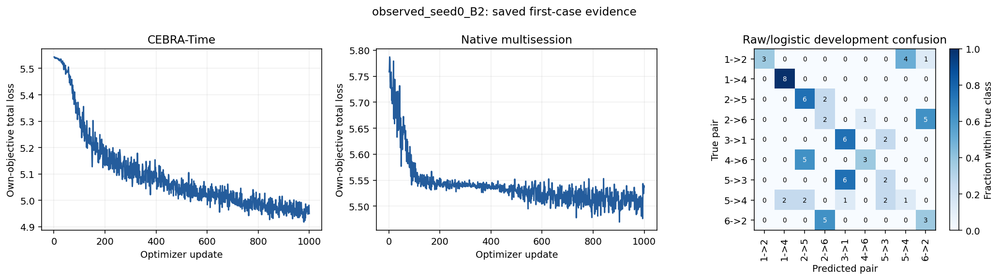<figcaption>Post-execution rendering of the same first case: B2, observed seed0, 17columns/3sessions; 144constructed training rows from 54 distinct training source identities; 72constructed exposed-development rows, nine ordered endpoint classes, cue[0,1)s in100msbins. Training curves have1,000updates each and different sampling objectives; compare within each curve. Raw/logistic pair balanced accuracy=47.22%, uniform reference11.11%. Matrix text=counts; color=row-normalized fraction; diagonal=recall. No biological uncertainty interval. Sources: authenticated case learning.json and confusions.json; no refitting or neural-array reads.</figcaption></figure>

## 11. Complete the fixed schedule without refitting the first case

        Reuse contains32cases; width adds16and references the eight completed B3 cases.
        Across both files there are18observed cases (six arms×three computational seeds) and
        30source-label diagnostic cases (six arms×five worlds at model seed0).
        A diagnostic world permutes joint-pair source labels within session and split before
        source selection and assembly. It preserves marginal counts while disrupting the
        original neural-label relation. These five worlds are a small diagnostic panel, not
        calibrated biological p-values. All48cases fit all representations/readouts/heads.

        The first case above is closed once and inserted into the same aggregate schema;
        the following cell trains only the remaining31or15cases. Actual instrumented counts,
        terminal attempt records and all source identities are independently reconciled.

In [13]:
results = execution.finish_remaining()
actual = execution.actual
count = 32 if PART == 'reuse' else 16
expected = {k: v * count // 48 for k, v in config['expected_fit_counts'].items()}
assert actual == expected
print('New cases:', count, 'actual instrumented fits/updates:', actual)
print('Total model fits excluding scalers:', sum((v for k, v in actual.items() if k != 'optimizer_updates')))
del case, execution, plans

Fitting observed_seed0_B3


Fitting observed_seed0_B5


Fitting observed_seed0_U3


Fitting observed_seed1_B2


Fitting observed_seed1_B3


Fitting observed_seed1_B5


... (22 outputs left out)

Fitting permuted61004_seed0_B3


Fitting permuted61004_seed0_B5


Fitting permuted61004_seed0_U3


New cases: 32 actual instrumented fits/updates: {'pca': 32, 'logistic': 384, 'lda': 384, 'cebra': 32, 'optimizer_updates': 64000, 'native': 32, 'svm': 384, 'knn': 384}
Total model fits excluding scalers: 1632


## 12. Scores, source use and learning curves

The report authenticates every completed case before collation. Balanced accuracy is mean class recall. Uniform pair reference=1/9; start/goal=1/6. The hypothetical perfect-single-endpoint pair reference=6/9 describes this sparse task, not a trained neural baseline. Report all computational repeats and diagnostic worlds. Repeated rows and seeds are not biological confidence intervals.

Metric rows: 1536 train/development confusion matrices: 3072


arm,encoder,decoder,head,mean_BA,min_BA,max_BA,train_BA,mean_train_development_gap,units,sessions,computational_repeats
B2,raw,logistic,pair,0.3796,0.2222,0.4722,1,0.6204,17,3,3
B2,raw,svm,pair,0.3657,0.125,0.5417,1,0.6343,17,3,3
B2,raw,knn,pair,0.2222,0.1667,0.2917,1,0.7778,17,3,3
B2,raw,lda,pair,0.3102,0.1667,0.4028,0.8819,0.5718,17,3,3
B2,pca,logistic,pair,0.3241,0.2639,0.4167,1,0.6759,17,3,3
B2,pca,svm,pair,0.3241,0.1667,0.4583,1,0.6759,17,3,3
B2,pca,knn,pair,0.2222,0.2083,0.2361,1,0.7778,17,3,3
B2,pca,lda,pair,0.1713,0.1389,0.2083,0.9907,0.8194,17,3,3
B2,cebra,logistic,pair,0.1806,0.09722,0.2639,1,0.8194,17,3,3
B2,cebra,svm,pair,0.1667,0.1111,0.2222,1,0.8333,17,3,3


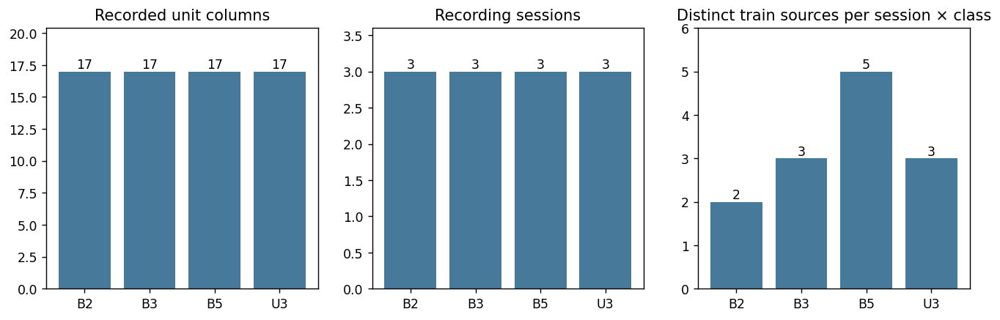

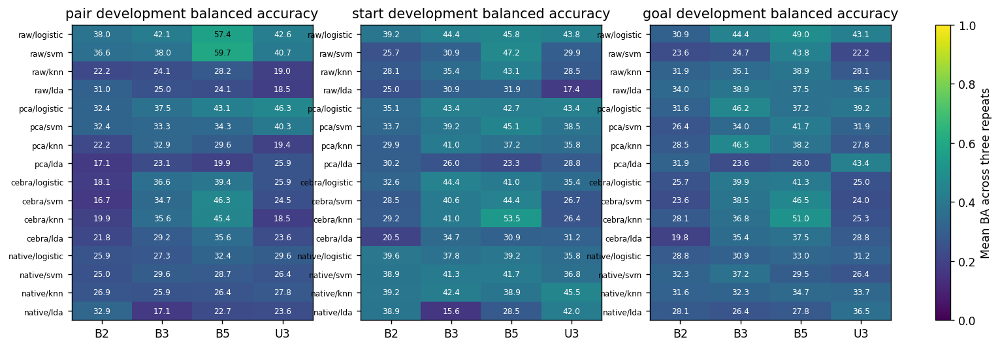

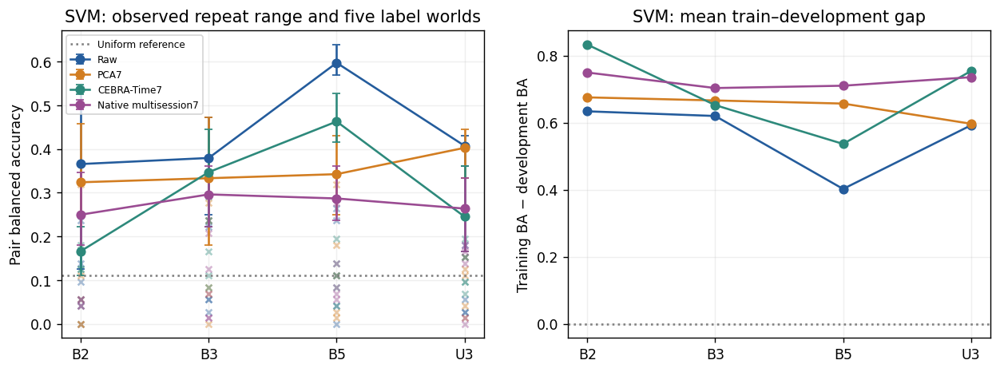

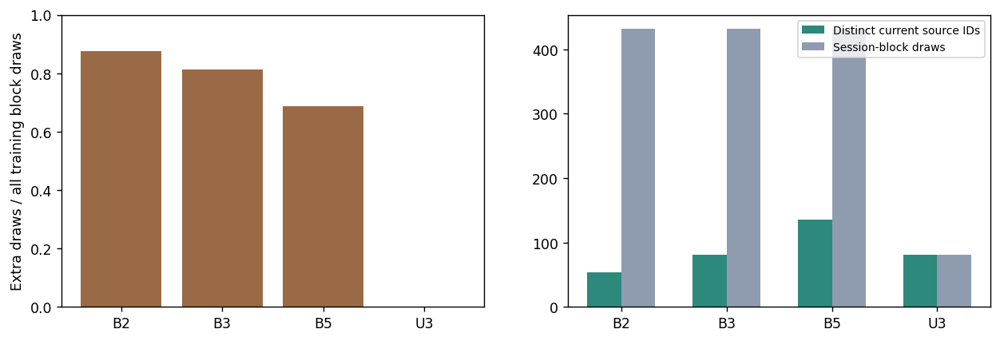

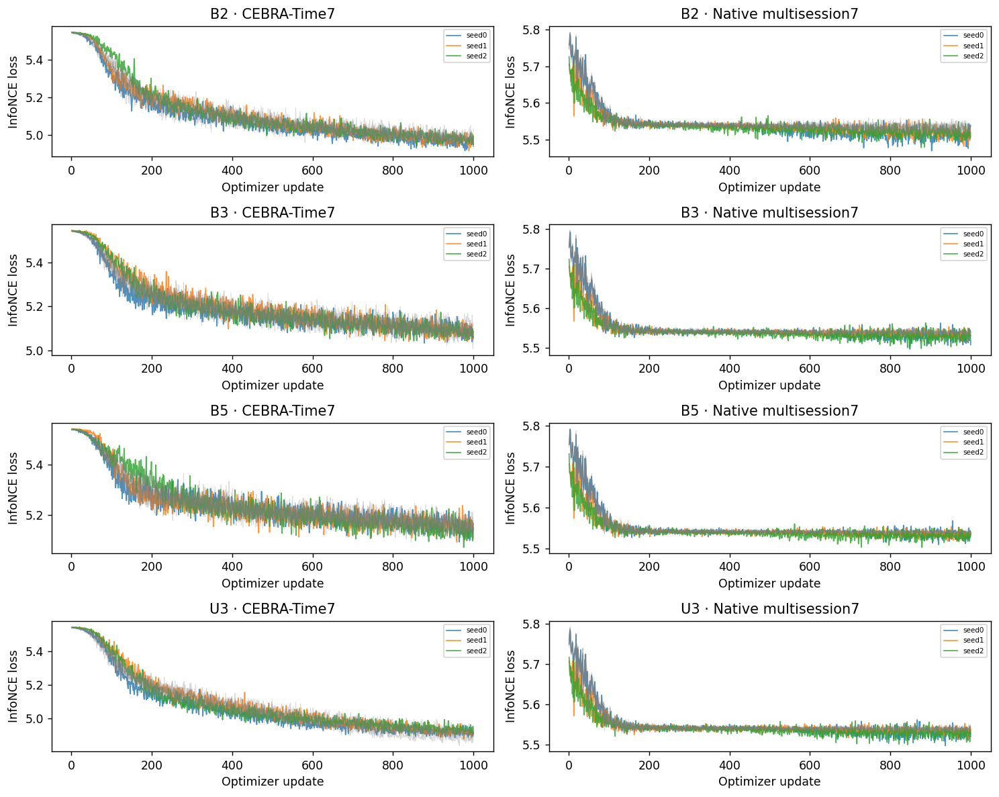

In [14]:
with frozen_models():
    report = create_report(RUN, PART, config, meta)
OUT = RUN / ('report_' + PART)
print('Metric rows:', report['metric_rows'], 'train/development confusion matrices:', report['confusion_matrices'])
display(HTML(table([r for r in report['summary'] if r['head'] == 'pair'])))

def show(group):
    for f in report['figures']:
        if f['group'] != group:
            continue
        path = OUT / f['file']
        assert study.sha(path) == f['sha256']
        if group in ('confusions', 'trajectories'):
            encoded = base64.b64encode(path.read_bytes()).decode()
            display(HTML('<details><summary>' + html.escape(path.stem) + '</summary><img style="max-width:100%" src="data:image/png;base64,' + encoded + '"><p>' + html.escape(f['caption']) + '</p></details>'))
        else:
            display(Image(filename=str(path)))
            display(HTML('<p>' + html.escape(f['caption']) + '</p>'))
show('overview')
show('learning')

## 13. Cue representation trajectories

Every observed arm/repeat is shown. Lines are class means over8constructed development rows and ten bin centers50–950ms from cue onset. Only the first three of seven coordinates are plotted; separate fits are not aligned. These describe learned cue representations, not maze paths or simultaneous neural dynamics.


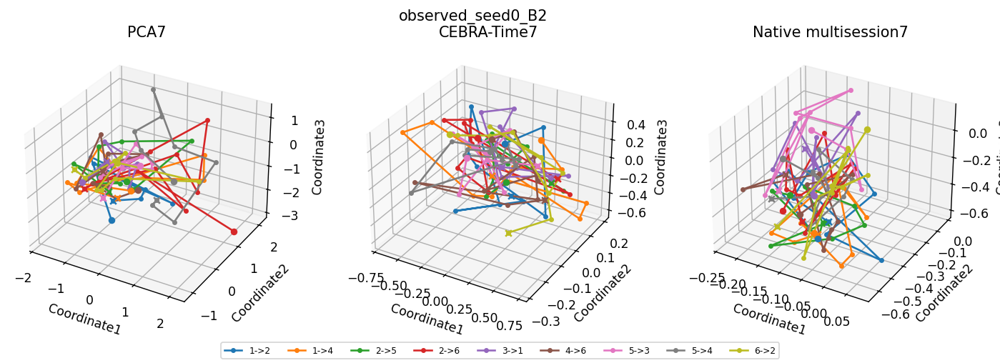


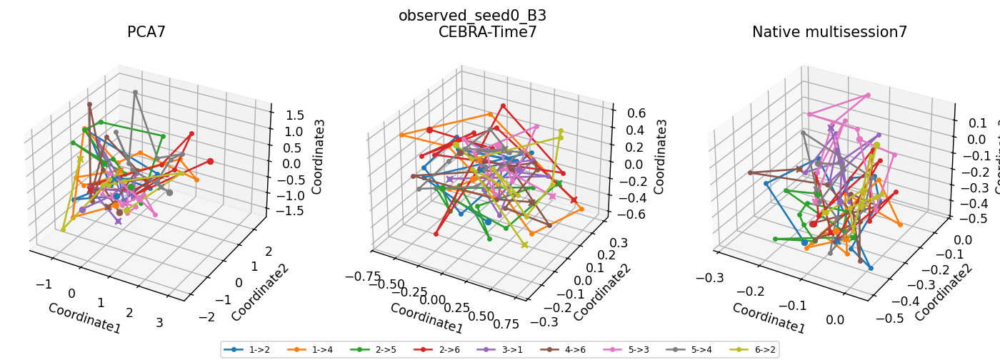


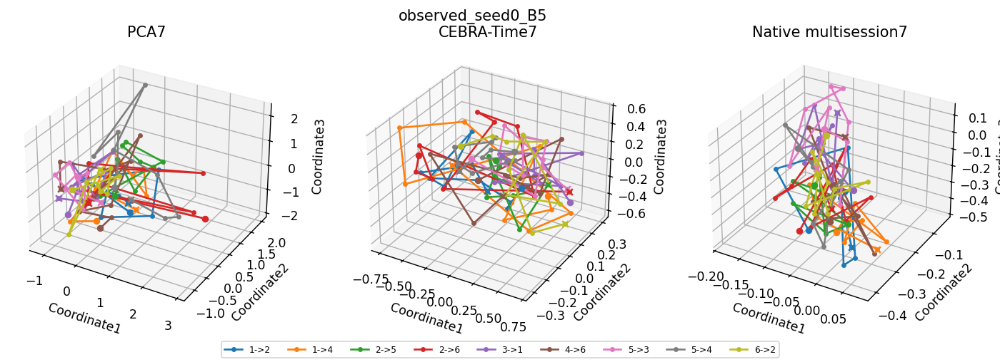


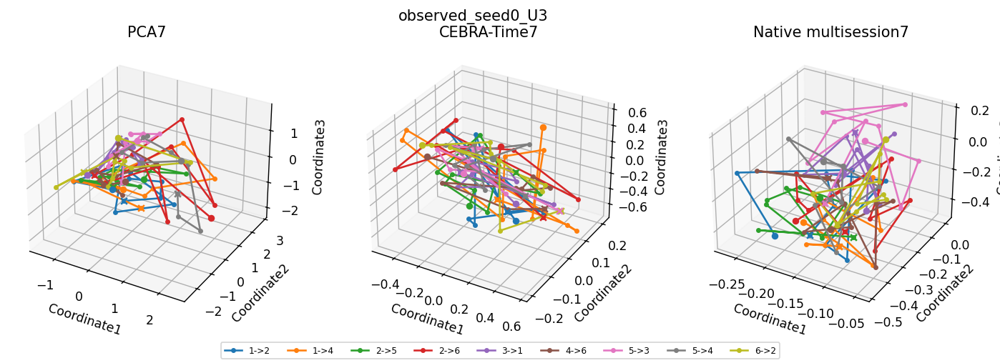


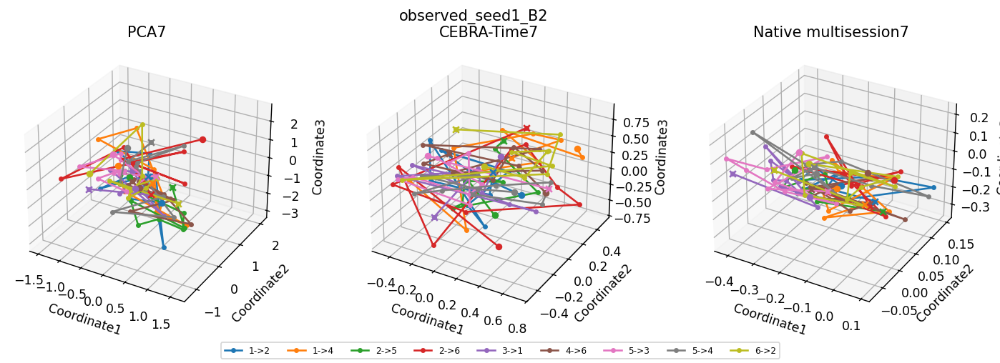


...


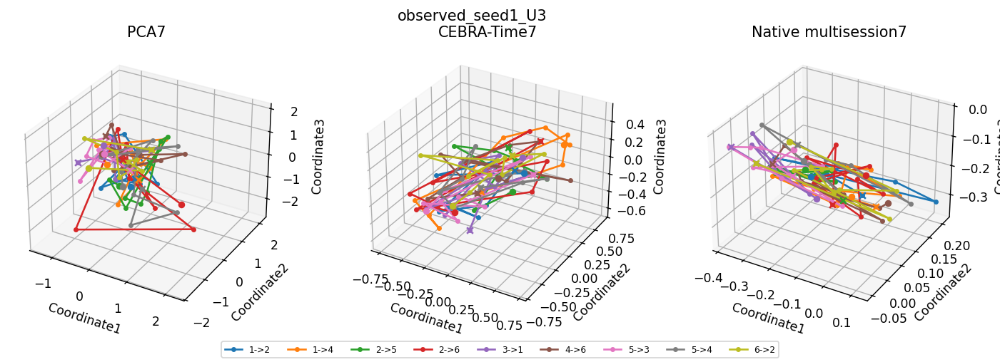


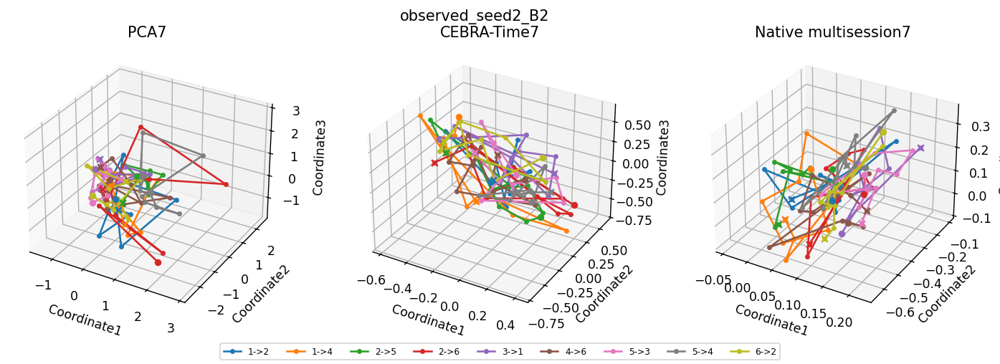


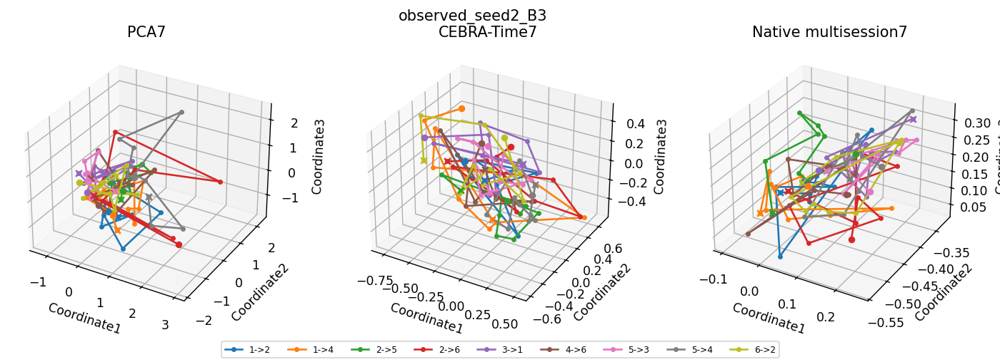


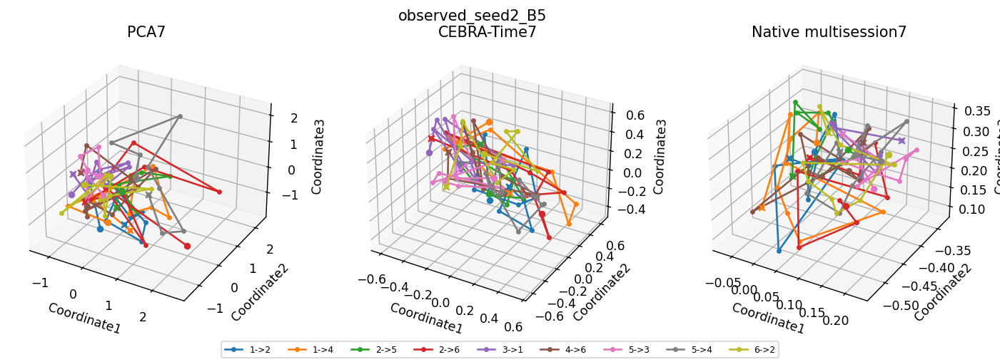


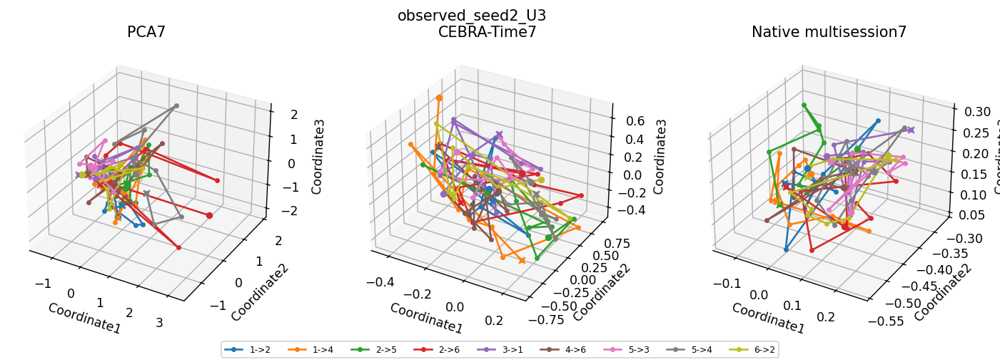

In [15]:
show('trajectories')

## 14. Confusions and best/worst error comparisons

Count and row-normalized pair confusions below show every model/readout at observed repeat0. The standalone report embeds an interactive explorer covering every repeat, label world, pair/start/goal head and training/development split. The complete matrices and per-class recalls are also numeric JSON/CSV. Best/worst arms are selected within each fixed encoder/readout using mean observed pairBA. U3 is a separate control and is excluded from primary reuse ranking. These views are post-hoc descriptions.

The complete interactive explorer is also embedded below with every matrix; no ignored result file is needed to view it after opening this executed notebook in a trusted Jupyter session or its offline HTML export. Static panels remain visible in viewers that do not run JavaScript.


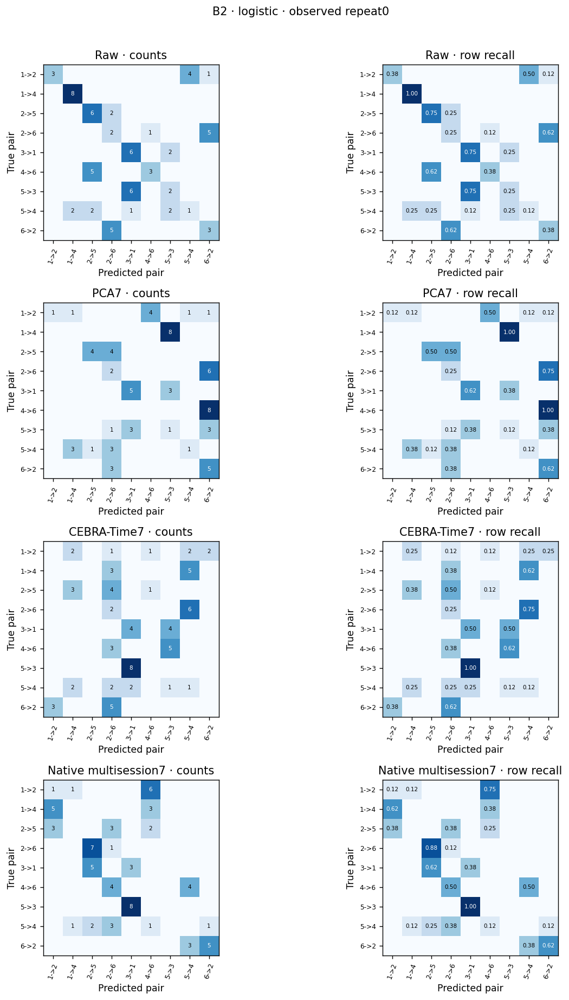


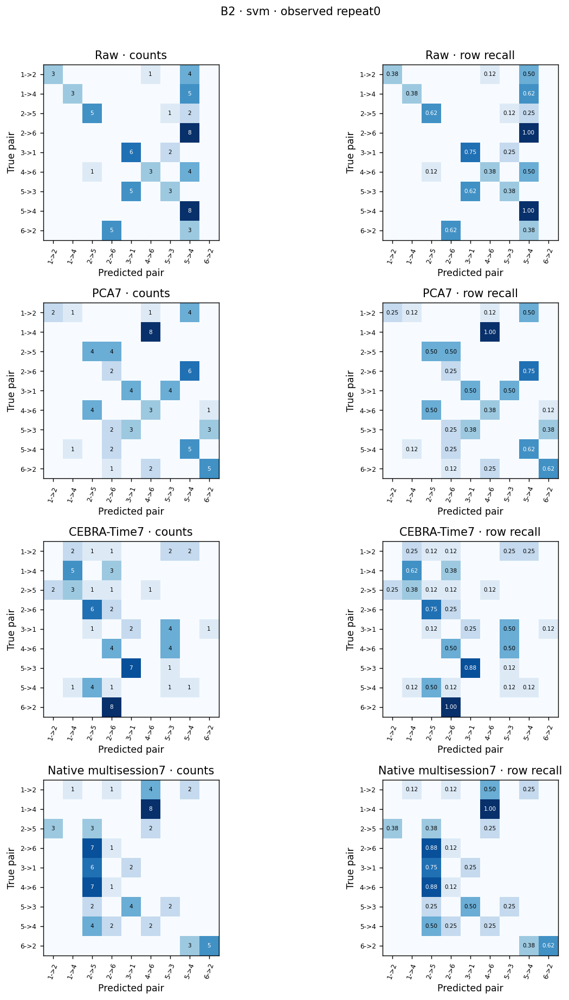


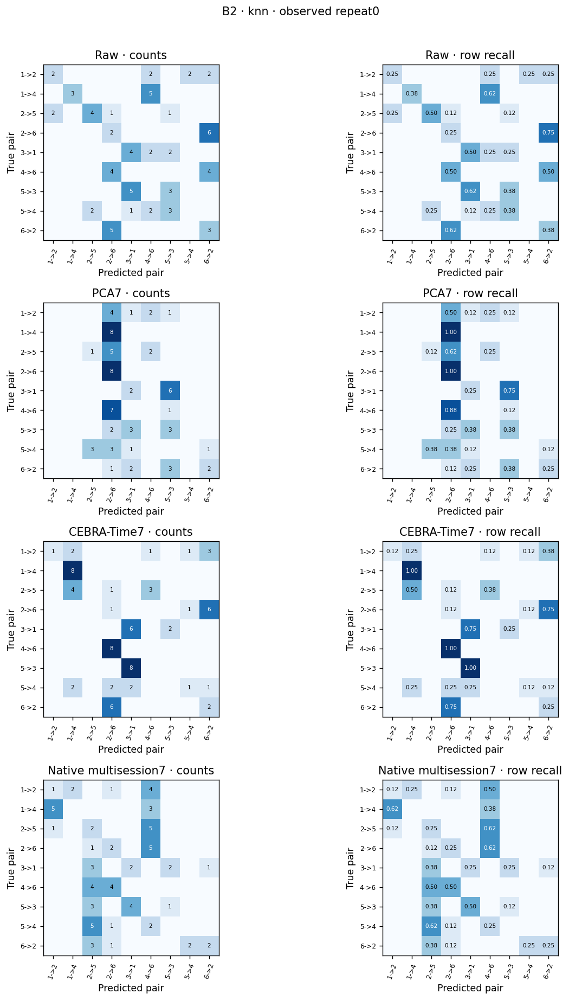


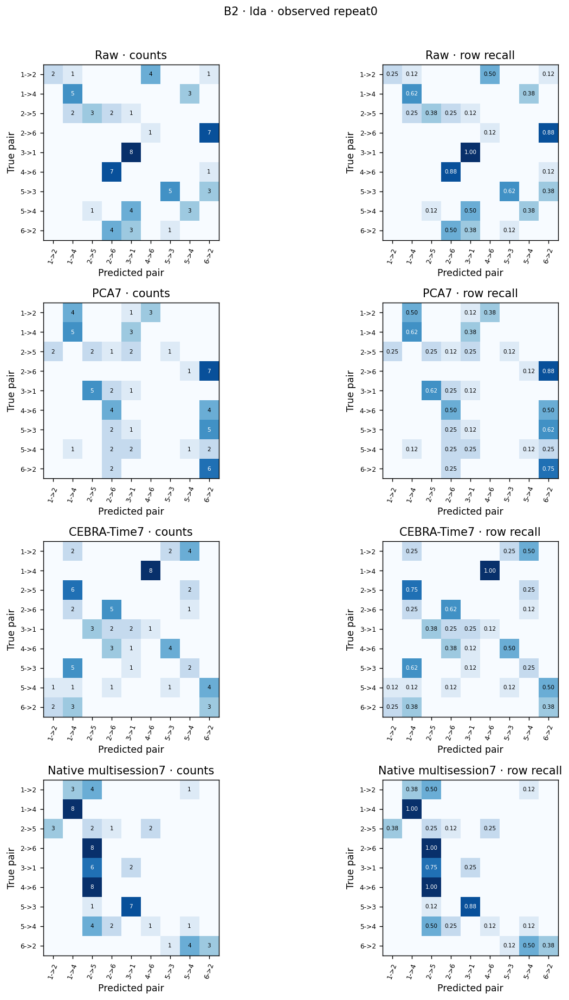


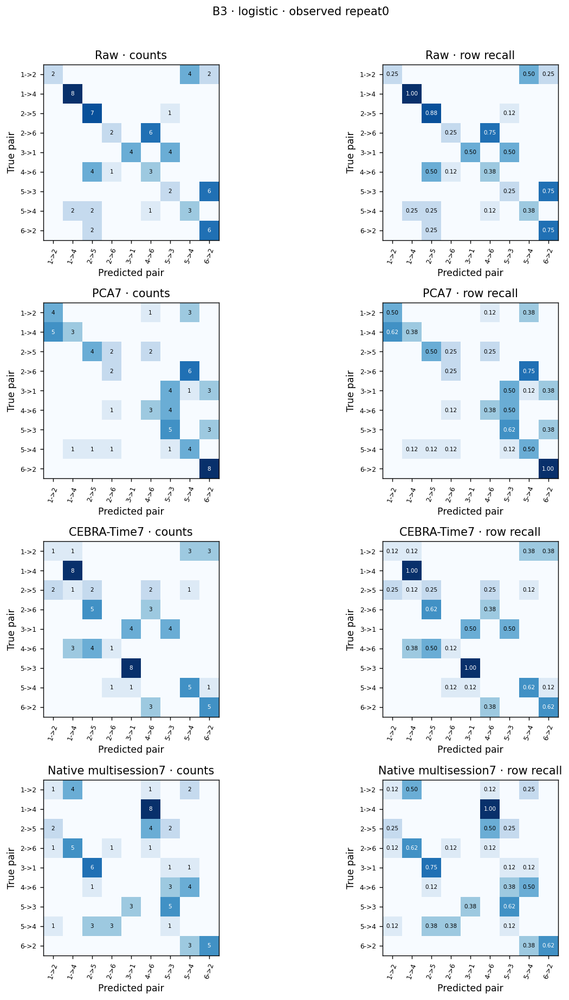


...


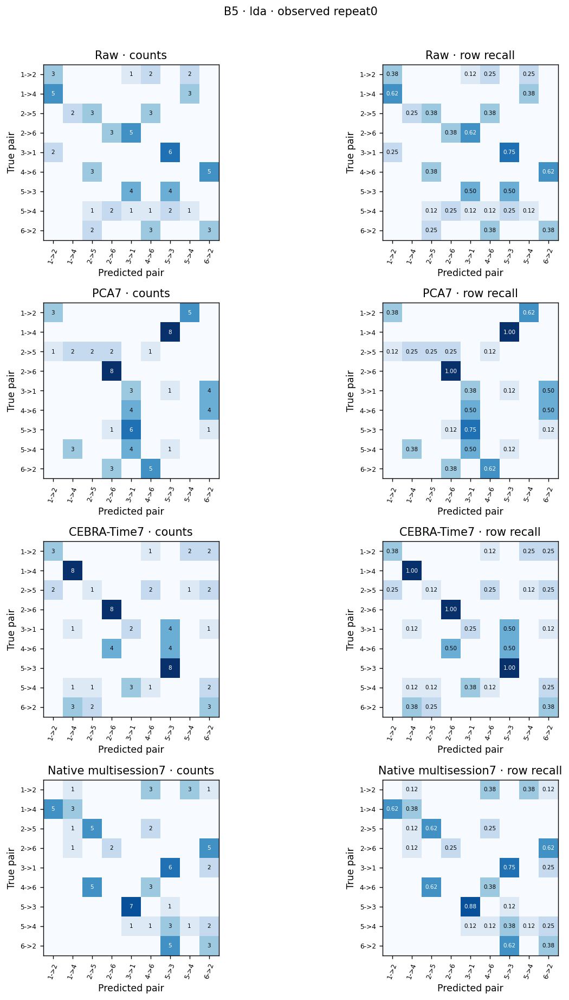


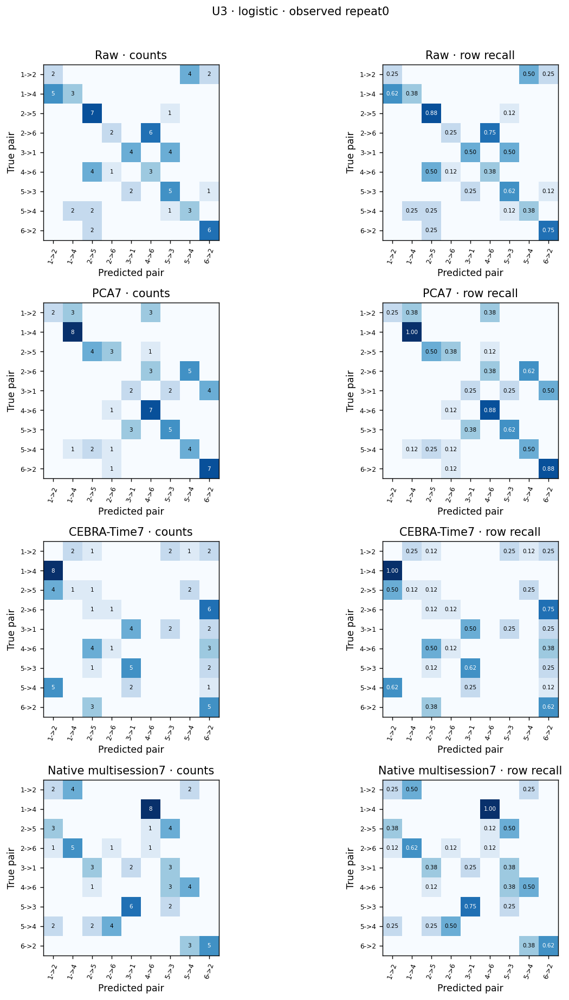


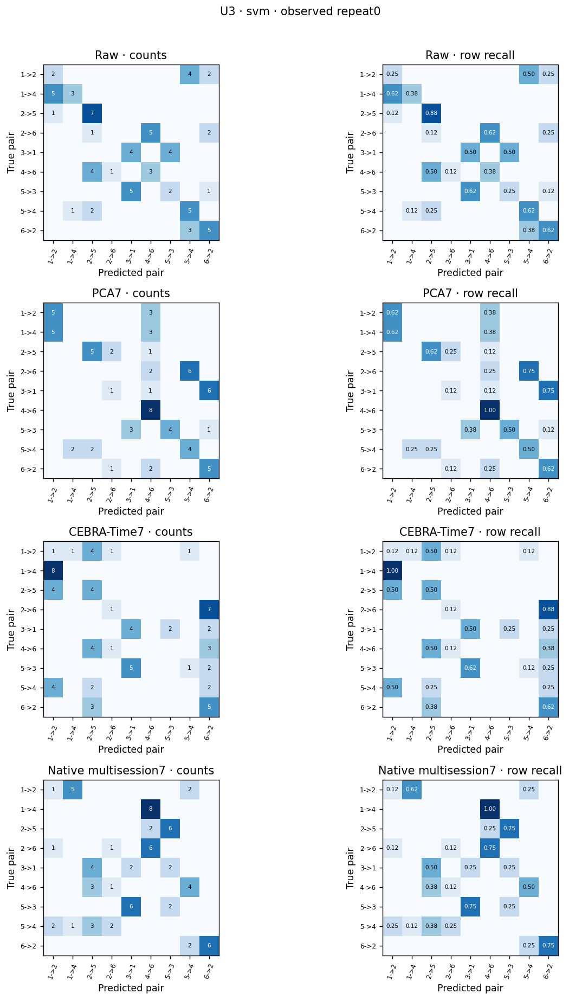


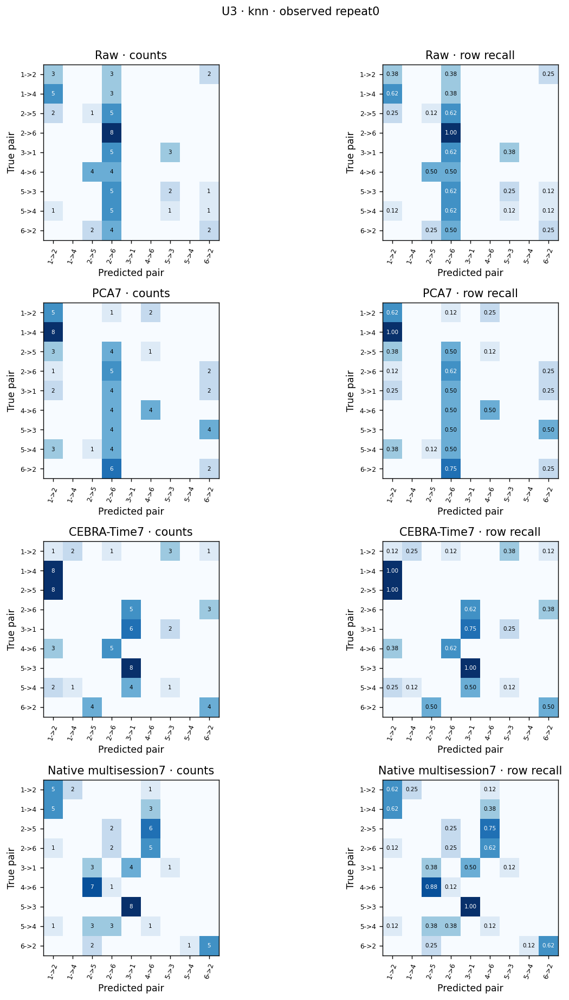


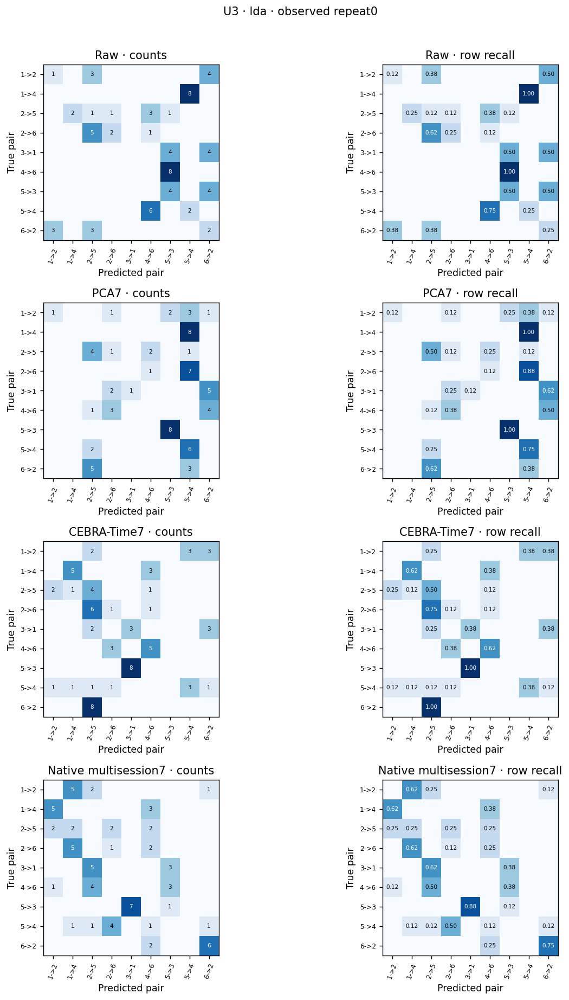

encoder,decoder,best,worst,best_mean_BA,worst_mean_BA,gap,best_ties,worst_ties
raw,logistic,B5,B2,0.5741,0.3796,0.1944,B5,B2
raw,svm,B5,B2,0.5972,0.3657,0.2315,B5,B2
raw,knn,B5,B2,0.2824,0.2222,0.06019,B5,B2
raw,lda,B2,B5,0.3102,0.2407,0.06944,B2,B5
pca,logistic,B5,B2,0.4306,0.3241,0.1065,B5,B2
pca,svm,B5,B2,0.3426,0.3241,0.01852,B5,B2
pca,knn,B3,B2,0.3287,0.2222,0.1065,B3,B2
pca,lda,B3,B2,0.2315,0.1713,0.06019,B3,B2
cebra,logistic,B5,B2,0.3935,0.1806,0.213,B5,B2
cebra,svm,B5,B2,0.463,0.1667,0.2963,B5,B2


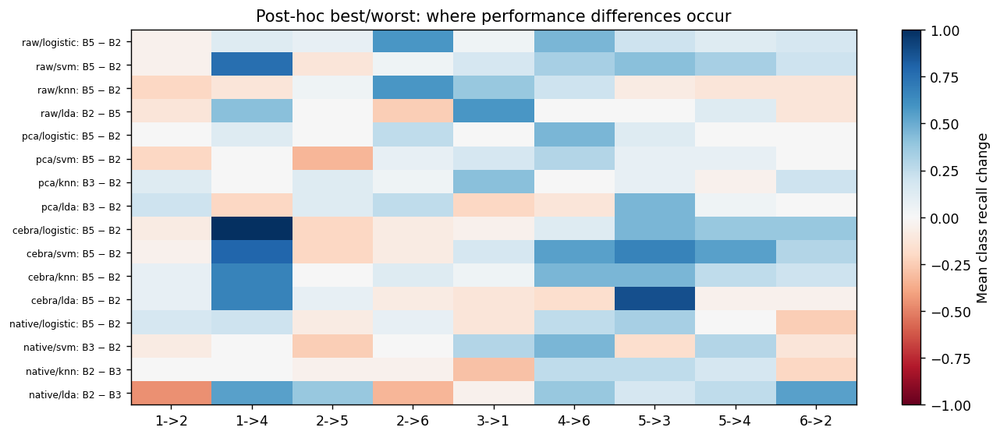

Interactive complete confusion explorer: /home/hongyi-home-lab/neuro_science/outputs/source-reuse-width-notebooks-20261115/real-01/report_reuse/report.html
Numeric complete matrices: /home/hongyi-home-lab/neuro_science/outputs/source-reuse-width-notebooks-20261115/real-01/report_reuse/confusion_matrices.json
Paired right→wrong / wrong→right tables: /home/hongyi-home-lab/neuro_science/outputs/source-reuse-width-notebooks-20261115/real-01/report_reuse/paired_error_switches.csv


/home/hongyi-home-lab/neuro_science/scratch/endpoint-notebook-runtime/lib/python3.13/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


In [16]:
from experiments.source_reuse_width_20261114.walkthrough_20261115.interpret import confusion_explorer
show('confusions')
display(HTML(table(report['best_worst'])))
show('errors')
print('Interactive complete confusion explorer:', OUT / 'report.html')
print('Numeric complete matrices:', OUT / 'confusion_matrices.json')
print('Paired right→wrong / wrong→right tables:', OUT / 'paired_error_switches.csv')
display(HTML(confusion_explorer(RUN, PART)))

## 15. All repeat/control scores and paired contrasts

        A mean can hide opposing seed changes. Here every observed seed and diagnostic world
        contributes to a score table, and paired changes use matched world/seed development
        rows. Positive AFTER−BEFORE favors the after arm. These ranges summarize computational
        variation and five constructed diagnostic worlds; they are not biological confidence
        intervals. Compare both absolute scores and paired changes. The table keeps every
        readout and head, including failures to improve, rather than selecting only winners.

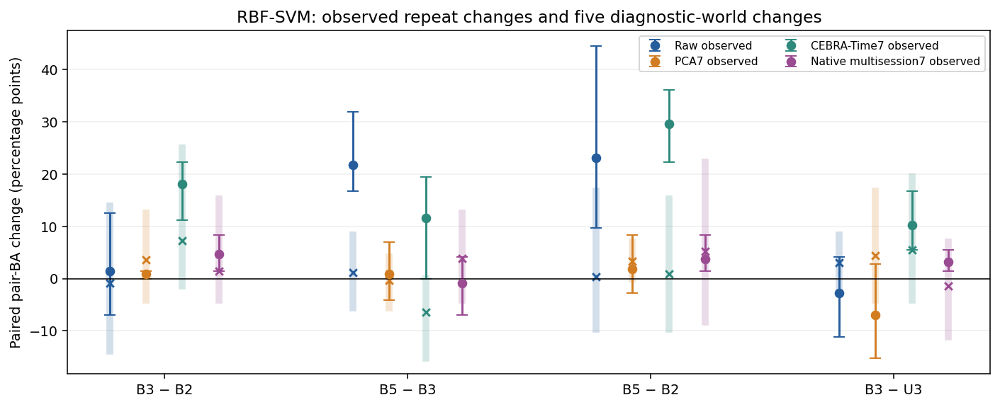

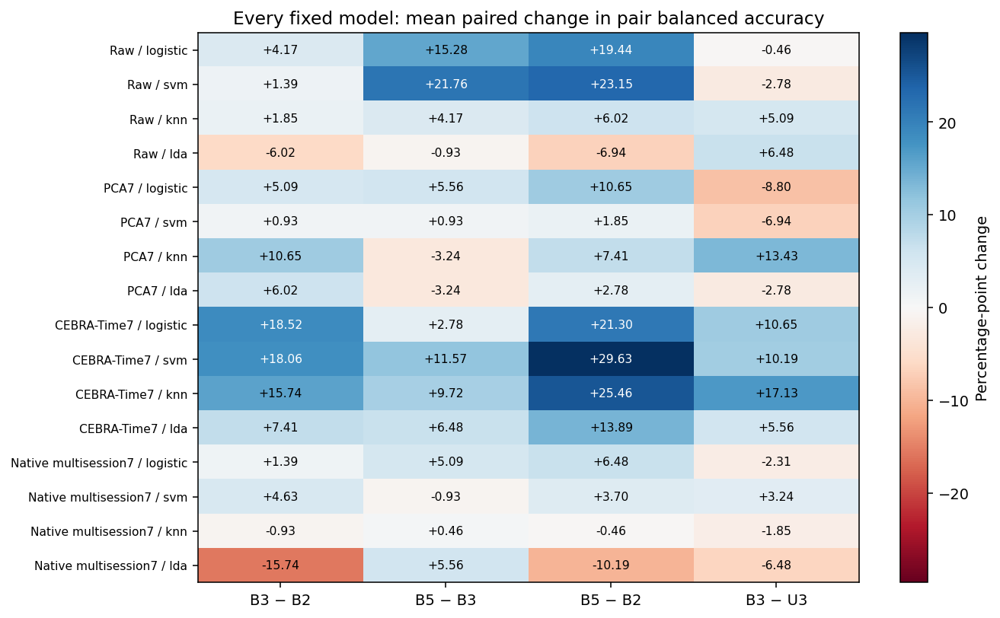

arm,encoder,decoder,head,observed_mean,observed_min,observed_max,diagnostic_mean,diagnostic_min,diagnostic_max,all_observed_above_five_diagnostics,mean_accuracy,mean_macro_f1
B2,raw,logistic,pair,0.3796,0.2222,0.4722,0.1472,0.04167,0.2639,False,0.3796,0.3437
B2,raw,logistic,start,0.3924,0.3646,0.4062,0.1604,0.1042,0.2083,True,0.4861,0.3346
B2,raw,logistic,goal,0.309,0.125,0.4896,0.1125,0.0625,0.2083,False,0.3611,0.3
B2,raw,svm,pair,0.3657,0.125,0.5417,0.1278,0,0.2361,False,0.3657,0.3394
B2,raw,svm,start,0.2569,0.2292,0.2812,0.1479,0.03125,0.2604,False,0.3426,0.1834
B2,raw,svm,goal,0.2361,0.1875,0.3333,0.1729,0.125,0.2188,False,0.3148,0.1544
B2,raw,knn,pair,0.2222,0.1667,0.2917,0.09444,0,0.1806,False,0.2222,0.2002
B2,raw,knn,start,0.2812,0.1875,0.3333,0.1437,0.03125,0.2083,False,0.2917,0.2509
B2,raw,knn,goal,0.3194,0.2604,0.3958,0.1667,0.1146,0.2396,True,0.3056,0.2912
B2,raw,lda,pair,0.3102,0.1667,0.4028,0.1528,0.01389,0.2361,False,0.3102,0.2976


before,after,encoder,decoder,head,observed_mean,observed_min,observed_max,positive_repeats,zero_repeats,diagnostic_mean,diagnostic_min,diagnostic_max,all_observed_above_diagnostic_contrasts
B2,B3,raw,logistic,pair,0.04167,0,0.08333,2,1,-0.03056,-0.1389,0.1111,False
B2,B3,raw,logistic,start,0.05208,0.02083,0.08333,3,0,-0.02292,-0.07292,0.07292,False
B2,B3,raw,logistic,goal,0.1354,-0.03125,0.2396,2,0,0.002083,-0.05208,0.09375,False
B2,B3,raw,svm,pair,0.01389,-0.06944,0.125,1,0,-0.008333,-0.1389,0.1389,False
B2,B3,raw,svm,start,0.05208,0.01042,0.1042,3,0,-0.03125,-0.07292,0.04167,False
B2,B3,raw,svm,goal,0.01042,-0.04167,0.1042,1,0,-0.02292,-0.1771,0.1354,False
B2,B3,raw,knn,pair,0.01852,-0.05556,0.1111,1,1,0.03333,-0.04167,0.125,False
B2,B3,raw,knn,start,0.07292,0.01042,0.1667,3,0,0.02917,-0.1042,0.1354,False
B2,B3,raw,knn,goal,0.03125,-0.04167,0.09375,2,0,0.01667,-0.1042,0.09375,False
B2,B3,raw,lda,pair,-0.06019,-0.1944,0.08333,1,0,-0.05,-0.125,0.04167,False


world,seed,arm,encoder,decoder,head,balanced_accuracy,accuracy,macro_f1,log_loss,train_BA,train_development_gap
observed,0,B2,raw,logistic,pair,0.4722222222222222,0.4722222222222222,0.45611070120874037,1.788366559941863,1.0,0.5277777777777778
observed,0,B2,raw,logistic,start,0.40625,0.5416666666666666,0.3304018912529551,1.3252065782820677,1.0,0.59375
observed,0,B2,raw,logistic,goal,0.4895833333333333,0.5416666666666666,0.4652038593215064,1.2678740493986587,1.0,0.5104166666666667
observed,0,B2,raw,svm,pair,0.4305555555555556,0.4305555555555556,0.4162552846763373,,1.0,0.5694444444444444
observed,0,B2,raw,svm,start,0.28125,0.375,0.21086515565746536,,1.0,0.71875
observed,0,B2,raw,svm,goal,0.1875,0.25,0.10410287813839558,,1.0,0.8125
observed,0,B2,raw,knn,pair,0.2916666666666667,0.2916666666666667,0.30094129292765265,17.90388889698726,1.0,0.7083333333333333
observed,0,B2,raw,knn,start,0.3333333333333333,0.3472222222222222,0.33271762811404754,14.456181317984269,1.0,0.6666666666666667
observed,0,B2,raw,knn,goal,0.3958333333333333,0.375,0.3937034642916995,17.334586811402872,1.0,0.6041666666666667
observed,0,B2,raw,lda,pair,0.3611111111111111,0.3611111111111111,0.37050264550264544,4.074970844307941,0.8680555555555556,0.5069444444444444


world,seed,before,after,encoder,decoder,head,delta_BA
observed,0,B2,B3,raw,logistic,pair,0.04166666666666663
observed,0,B2,B3,raw,logistic,start,0.020833333333333315
observed,0,B2,B3,raw,logistic,goal,-0.03125
observed,0,B2,B3,raw,svm,pair,-0.013888888888888895
observed,0,B2,B3,raw,svm,start,0.010416666666666685
observed,0,B2,B3,raw,svm,goal,0.10416666666666669
observed,0,B2,B3,raw,knn,pair,-0.05555555555555558
observed,0,B2,B3,raw,knn,start,0.041666666666666685
observed,0,B2,B3,raw,knn,goal,-0.04166666666666663
observed,0,B2,B3,raw,lda,pair,-0.19444444444444445


The tables above contain every model/readout/head; pair SVM is a readable cross-model slice, not the only analysis.


In [17]:
from experiments.source_reuse_width_20261114.audit.deliver import control_summaries, supplemental_figures
import csv
with frozen_models():
    scores, contrasts = control_summaries(RUN, PART)
    supplement = RUN / ('walkthrough_' + PART)
    supplement.mkdir()
    study.write_csv(supplement / 'score_control_summary.csv', scores)
    study.write_csv(supplement / 'contrast_summary.csv', contrasts)
    supplement_figures = supplemental_figures(supplement, contrasts, PART)
for figure in supplement_figures:
    display(Image(filename=str(supplement / figure['file'])))
    display(HTML('<p>' + html.escape(figure['caption']) + '</p>'))
display(HTML('<details><summary>Every score:3observed seeds and5diagnostic worlds</summary>' + table(scores) + '</details>'))
display(HTML('<details><summary>Every paired contrast and its repeat/control ranges</summary>' + table(contrasts) + '</details>'))
for filename, label in [('metrics.csv', 'Every case score'), ('paired_contrasts.csv', 'Every matched seed/world contrast')]:
    with (OUT / filename).open() as handle:
        full_rows = list(csv.DictReader(handle))
    keep = ('world', 'seed', 'arm', 'before', 'after', 'encoder', 'decoder', 'head', 'balanced_accuracy', 'accuracy', 'macro_f1', 'log_loss', 'train_BA', 'train_development_gap', 'delta_BA')
    display(HTML('<details><summary>' + label + '</summary>' + table([{k: r[k] for k in keep if k in r} for r in full_rows]) + '</details>'))
print('The tables above contain every model/readout/head; pair SVM is a readable cross-model slice, not the only analysis.')

## 16. Interpret this execution and connect errors to the research question

        The following interpretation is generated from this run's saved scores and paired
        changes. All conclusions remain exploratory. An improvement in B5 over B2 couples
        increased distinct-source diversity with less repetition and different weighting/
        recombination. B3 versus U3 holds the source identities fixed but changes row count
        and optimization exposure. Wider populations add session blocks, columns and total
        measured source identities together. These comparisons do not isolate neurons per se.

In [18]:
from experiments.source_reuse_width_20261114.walkthrough_20261115.interpret import explain
with frozen_models():
    display(HTML(explain(RUN, PART, scores, contrasts)))
print('No classes were deleted between arms. A source associated with many wrong assembled rows is not an independently demonstrated bad trial.')
print('Common development rows are reused across seeds;216pooled predictions are3passes over72rows, not216independent trials.')

No classes were deleted between arms. A source associated with many wrong assembled rows is not an independently demonstrated bad trial.
Common development rows are reused across seeds;216pooled predictions are3passes over72rows, not216independent trials.


## 8. What this can establish, and the issue29 follow-up

The primary reuse comparison couples greater measured source diversity with less repetition and changed weighting/recombination. U3/B3 holds measured sources fixed. The width comparison adds sessions, columns and total sources together; native encoder counts and per-session batch exposure also change. All conclusions concern this condition-level, known-label-assembled and historically exposed-development assay.

The error handoff records retained/removed column aliases and common-row prediction changes. No class is deleted between arms. Spatial-map availability is unknown: compact inputs lack authenticated field location, occupancy/reliability, map-source trials and coordinate joins. Therefore lost-field explanations from issue29 remain untested. Navigation place fields cannot be substituted with cue confusion labels. This gap does not erase the completed source-reuse/width measurements.

Every saved encoder/readout was reloaded under fit guards and reproduced train/development transformations and predictions. The final run receipt and independent numeric/scientific review are recorded after both notebooks finish. No prior experiment has been overwritten.

In [19]:
assert all((study.sha(PROJECT / path) == digest for path, digest in pins.items()))
assert all((study.sha(OUT / f['file']) == f['sha256'] for f in report['figures']))
print('Completed experiment', PART, 'with', count, 'new cases and', len(report['figures']), 'figures.')
print('Independent cross-run receipt/numeric review follows completion of both files.')

Completed experiment reuse with 32 new cases and 34 figures.
Independent cross-run receipt/numeric review follows completion of both files.


## Reading this result responsibly

        **Supported:** relative condition-level recovery for these constructions, models,
        nine labels and exposed-development sources. Once-only recovery can test whether
        assembly repetition is necessary for an association; it cannot establish general
        sampling validity, independent population dynamics or generalization to unseen animals.

        **Not measured here:** new recordings, untouched natural-trial accuracy, aligned
        cross-fit neural geometry, spatial field loss, navigation transfer or class deletion.
        The cue lines above are bin-wise latent class means, not time-resolved decoding scores;
        no extra per-time decoder was trained. A fall in a selected class's recall may guide
        follow-up, but cannot identify a harmful session or lost place field without the
        corresponding authenticated spatial measurements.

        **Reproducibility:** fixed source input and code hashes, configuration, runtime identity,
        model updates, fit counts, failures, complete confusion data and guarded reloads are
        recorded with this execution. The final external numeric/claim/privacy audit and the
        comparison with the previous accepted execution are linked in the companion validation
        ledger. The executed notebook's outputs are evidence of the actual cells above; no
        fresh prediction has been substituted into an old output cell.

## Editorial correction after execution

The methods paragraph was corrected to describe same-session/source-trial grouping without asserting verified simultaneous recording. Every executed code cell and output is unchanged. The frozen training-source notebooks and run snapshot retain the original wording as execution provenance; this reviewed copy supersedes that sentence. A labelled first-case figure renders authenticated saved aggregate records after the original Agg cell displayed only text. No model was refitted for either change. Generic absolute output/runtime paths in preserved stdout describe the execution host; they are historical local paths, not public links. All figures and the confusion explorer needed to read this notebook are embedded.